# Modularity on the Karate Club Graph
DSC212: Graph Theory Module

This notebook implements spectral modularity maximization with recursive
bisection "Modularity and community structure innetworks", 

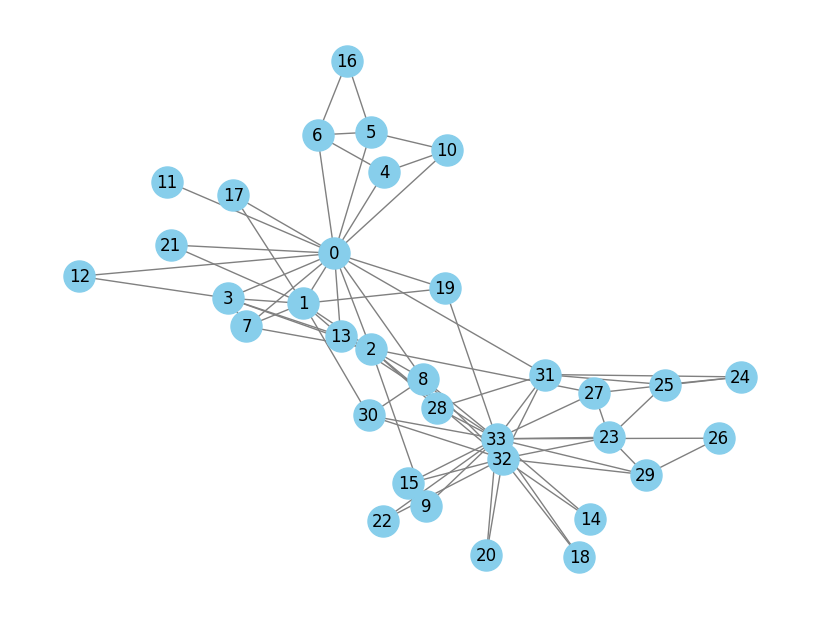

In [78]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.karate_club_graph()

pos = nx.spring_layout(G, seed=42)   # fixed layout

plt.figure(figsize=(8, 6))
nx.draw(G, pos, with_labels=True, node_color="skyblue",
        node_size=500, edge_color="gray")
plt.show()

## 1. The Karate Club data
In the early 1970s, Wayne Zachary observed 34 members of a university karate
club for two years. Each member is a node, and an edge means two members
interacted often outside class. The graph has **34 nodes and 78 edges**.

During the study the instructor ("Mr. Hi", node 0) and the administrator
(node 33) disagreed, and the club split into two factions. The friendships were
recorded *before* the split, so we can ask: can a method that sees only the graph
structure recover the split?

In [79]:
import numpy as np
import numpy.linalg as al
A = nx.to_numpy_array(G, weight=None)
print(A)

[[0. 1. 1. ... 1. 0. 0.]
 [1. 0. 1. ... 0. 0. 0.]
 [1. 1. 0. ... 0. 1. 0.]
 ...
 [1. 0. 0. ... 0. 1. 1.]
 [0. 0. 1. ... 1. 0. 1.]
 [0. 0. 0. ... 1. 1. 0.]]


## 2. Why modularity?
Minimizing the number of cut edges gives useless answers. Splitting off a
single member cuts very few edges, so it looks "good" even though it is not a
community. Likewise, scoring "edges inside minus edges cut" is best when
nobody is split at all.

Modularity fixes this by comparing the observed edges against a **random
baseline** that keeps every node's degree. A split scores well only if its
groups have **more internal edges than chance predicts**.

In [80]:
k=np.sum(A,axis=1)
m=np.sum(k)/2
z = np.outer(k, k) / (2 * m)
B=A-z
B

array([[-1.64102564,  0.07692308, -0.02564103, ...,  0.38461538,
        -1.23076923, -1.74358974],
       [ 0.07692308, -0.51923077,  0.42307692, ..., -0.34615385,
        -0.69230769, -0.98076923],
       [-0.02564103,  0.42307692, -0.64102564, ..., -0.38461538,
         0.23076923, -1.08974359],
       ...,
       [ 0.38461538, -0.34615385, -0.38461538, ..., -0.23076923,
         0.53846154,  0.34615385],
       [-1.23076923, -0.69230769,  0.23076923, ...,  0.53846154,
        -0.92307692, -0.30769231],
       [-1.74358974, -0.98076923, -1.08974359, ...,  0.34615385,
        -0.30769231, -1.8525641 ]], shape=(34, 34))

## 3. The modularity matrix
$$B_{ij} = A_{ij} - \frac{k_i k_j}{2m}$$

$B_{ij}>0$ means $i$ and $j$ are connected *more* than chance, and $B_{ij}<0$
means *less*. For any partition, the modularity is

$$Q = \frac{1}{2m}\sum_{c}\sum_{i,j\in c} B_{ij}.$$

For two groups with labels $s_i=\pm1$, using $\delta(c_i,c_j)=\frac{s_is_j+1}{2}$,

$$Q = \frac{1}{4m}\, s^\top B s,$$

because $B\mathbf{1}=\mathbf{0}$ removes the constant term. This also means the
trivial partition (everyone together) has $Q=0$.

### The random baseline
Give node $i$ exactly $k_i$ half-edges ("stubs"). There are $2m$ stubs in total.
Pair them uniformly at random. Each stub of node $i$ is matched with one of the
other $2m-1$ stubs, so the expected number of edges between $i$ and $j$ is

$$\mathbb{E}[X_{ij}] = k_i k_j \cdot \frac{1}{2m-1} \approx \frac{k_i k_j}{2m}.$$

Summing over $j$ gives $\sum_j \frac{k_i k_j}{2m} = k_i$, so the baseline
preserves every node's degree.

In [ ]:
def get_part(nodes):
    n = len(nodes)
    part = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            part[i][j] = B[nodes[i]][nodes[j]]   # pick rows/columns of B for this group
    return part

T = 0.03   # threshold below which an eigenvector entry counts as "undecided"

def split_group(nodes):
    Bg = get_part(nodes)                 # plain block of B
    l, v = al.eigh(Bg)
    lam = l[-1]
    u = v[:, -1]                         # leading eigenvector

    if lam <= 1e-10:                     # handout's stopping rule
        return None

    # clear scores go by sign; near-zero scores are undecided
    plus      = [nodes[a] for a in range(len(nodes)) if u[a] >  T]
    minus     = [nodes[a] for a in range(len(nodes)) if u[a] < -T]
    undecided = [nodes[a] for a in range(len(nodes)) if abs(u[a]) <= T]

    # each undecided node joins the group where its total B-weight is larger
    for node in undecided:
        to_plus  = sum(B[node][j] for j in plus  if j != node)
        to_minus = sum(B[node][j] for j in minus if j != node)
        if to_plus >= to_minus:
            plus.append(node)
        else:
            minus.append(node)

    if len(plus) == 0 or len(minus) == 0:   # everyone on one side
        return None
    return plus, minus

def modularity(partition):
    total = 0
    for c in partition:
        for i in c:
            for j in c:
                total = total + B[i][j]
    return total / (2 * m)


## Modification: handling nodes with near-zero eigenvector entries

**Observation.** With the handout's rule (sign of $(u_1)_i$), node 11 is separated
from node 0. Node 11 has degree 1 and its only neighbour is node 0. The trace
above shows why: in the 16-node group at iteration 2 its entry is about 0.013 in
magnitude, and node 0's is about 0.007. When an entry is that close to zero, its
sign says almost nothing about where the node belongs. The plain sign rule put
node 11 on the opposite side from its only neighbour, and a third iteration then
isolated it as a community of one (5 communities, Q = 0.4094).

**Modification.** Entries with $|(u_1)_i| \le 0.03$ are treated as *undecided*.
Entries above $+0.03$ and below $-0.03$ are assigned by sign as before. Each
undecided node joins the group where its total modularity weight
$\sum_j B_{ij}$ over that group's clear members is larger.

**Why this removes the bias.** A first attempt used the rule
$(u_1)_i > 0.03$ for one group and everything else for the other. That is
biased in two ways. First, all near-zero nodes always fall into the "minus"
group, whatever their neighbours are. Second, the result depends on the sign
that the eigensolver returns, because $u_1$ and $-u_1$ are equally valid, so a
different machine could give a different partition. The rule above fixes both:
- Clear entries are handled by sign, so flipping $u_1$ only swaps the names of
  the two groups.
- Undecided nodes are decided by $B$, the same quantity modularity is built
  from, not by the sign or the label order. A node that has real edges into a
  group, relative to the null model, joins it (node 11 has $B_{11,0}\approx0.90$).
- Neither choice depends on which group is called plus or minus.

**Result.** 2 communities (Q = 0.3715) at iteration 1, then 4 communities
(Q = 0.4174) at iteration 2, with node 11 kept with node 0.

**Limitations.**
- The value 0.03 was chosen by inspecting this graph; it is not derived from
  the modularity theory.
- The result is not the optimum. Moving node 23 into {24, 25, 27, 28, 31} raises
  Q to 0.4198, the best-known value for this graph.
- The handout's plain sign rule gives 5 communities with Q = 0.4094.

In [82]:
partition = [list(range(34))]      # start: everyone in one group
history = []

while True:
    new_partition = []
    changed = False

    for g in partition:
        result = split_group(g)            # None, or (plus, minus)
        if result is None:
            new_partition.append(g)        # cannot split, keep it
        else:
            new_partition.append(result[0])
            new_partition.append(result[1])
            changed = True

    if not changed:                        # nothing split this round: done
        break

    partition = new_partition
    history.append((partition, modularity(partition)))

for i in range(len(history)):
    print("ittration ", i + 1, ":", len(history[i][0]), "communities, Q =", round(history[i][1], 4))

ittration  1 : 2 communities, Q = 0.3715
ittration  2 : 4 communities, Q = 0.4174


## 5. Recursive bisection and the stopping rule
For a community $C$ we take the block $B^{(C)}$ of the global $B$ (rows and
columns of the nodes in $C$) and compute its leading eigenpair.

- If $\lambda_1^{(C)}>0$, a split may raise modularity, so we split $C$ by the
  signs of its eigenvector.
- If $\lambda_1^{(C)}\le 0$, no choice of $s$ gives a positive gain, so $C$ is
  final.

We repeat on every new group until no group can be split. Throughout, $A$, $k$,
$m$ and $B$ stay **fixed** at their full-graph values. Only the partition
changes, and Q is one global number for the whole partition.

In [ ]:
def top_eigenvalue(nodes):
    Bg = get_part(nodes)          
    l, v = al.eigh(Bg)
    return l[-1]


### Eigenvalues and members at each iteration
For every iteration we print each community's members, size and largest
eigenvalue $\lambda_1$. A community with $\lambda_1>0$ is a candidate for the
next split, and one with $\lambda_1\le 0$ is final.

In [84]:

from IPython.display import display, HTML

all_history = [([list(range(34))], 0.0)] + history

def top_eigenvalue(nodes):
    return al.eigh(get_part(nodes))[0][-1]

css = """<style>
.t{border-collapse:collapse;margin:4px 0 18px 0;font-size:13px;width:100%}
.t th{background:#f2f2f2;text-align:left;padding:6px 10px;border-bottom:2px solid #bbb}
.t td{padding:6px 10px;border-bottom:1px solid #e3e3e3;vertical-align:top}
.t td.m{width:55%;line-height:1.5}
.fin{color:#2e7d32;font-weight:600}
</style>"""

html = css
for i, (partition, Q) in enumerate(all_history):
    html += f"<b>Iteration {i}</b> &nbsp;·&nbsp; {len(partition)} communities &nbsp;·&nbsp; Q = {Q:.4f}"
    html += "<table class='t'><tr><th>Community</th><th>Size</th><th>λ₁</th><th>Status</th><th>Members</th></tr>"
    for c, comm in enumerate(partition):
        members = sorted(comm)
        lam = top_eigenvalue(members)
        status = "<span class='fin'>final</span>" if lam <= 1e-10 else "splits next"
        html += (f"<tr><td>{c}</td><td>{len(members)}</td><td>{lam:.4f}</td>"
                 f"<td>{status}</td><td class='m'>{', '.join(map(str, members))}</td></tr>")
    html += "</table>"

display(HTML(html))

Community,Size,λ₁,Status,Members
0,34,4.9771,splits next,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33"
Community,Size,λ₁,Status,Members
0,16,2.9441,splits next,"0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21"
1,18,2.5041,splits next,"8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33"
Community,Size,λ₁,Status,Members
0,5,2.1470,splits next,"4, 5, 6, 10, 16"
1,11,2.5813,splits next,"0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21"
2,5,1.8759,splits next,"24, 25, 27, 28, 31"
3,13,2.3563,splits next,"8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33"


### What the splits show
| Iteration | Communities | Q |
|---|---|---|
| 1 | 2 | 0.3715 |
| 2 | 4 | 0.4081 |
| 3 | 5 | 0.4094 |

- **Iteration 1:** the first split gives two groups of 16 and 18 nodes, close to
  the real faction split. [Compare with `G.nodes[i]['club']` and write how many
  nodes differ.]
- **Iteration 2:** each group splits again, giving 4 communities.
- **Iteration 3:** node 11 is separated on its own. It has degree 1 (only node 0),
  so it has no edges to the group it was placed in. Its block gives
  $\lambda_1=-0.0064 = -k^2/2m$, matching $B_{ii}=-1/156$.
- Q rises at every step, and the final value matches NetworkX's modularity.

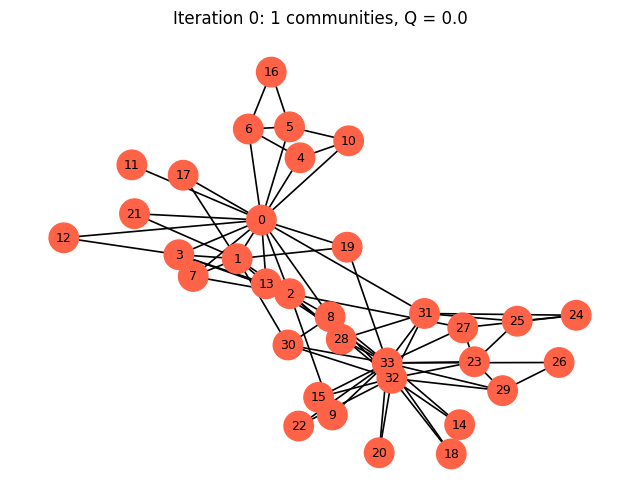

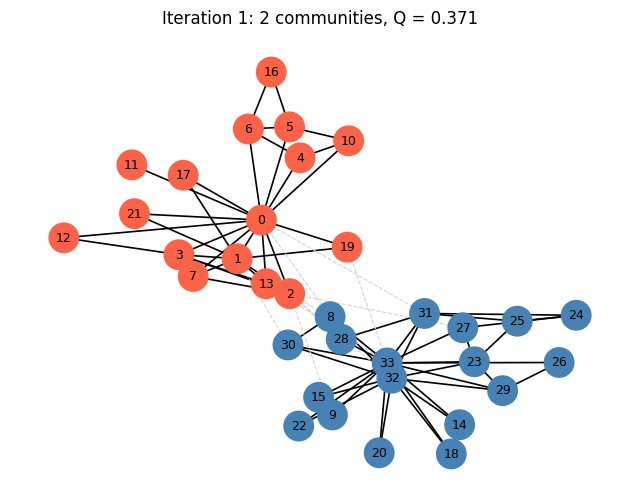

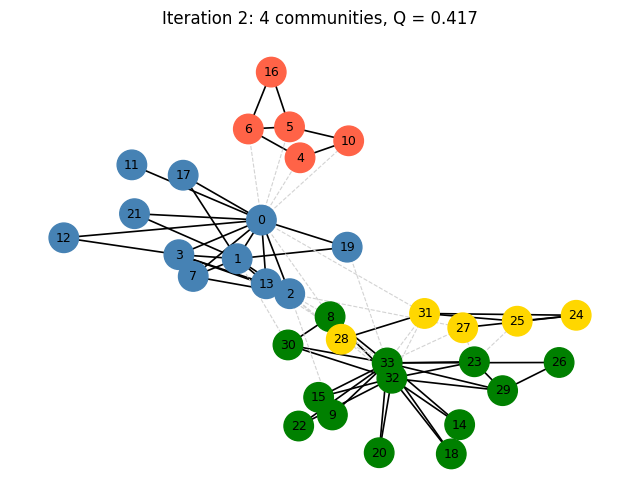

In [85]:
colors_list = ["tomato", "steelblue", "gold", "green", "purple",
               "orange", "pink", "brown", "cyan", "gray"]

pos = nx.spring_layout(G, seed=42)       # fixed layout, made once

for i in range(len(all_history)):
    partition, Q = all_history[i]

    # which community each node belongs to
    label = {}
    for c in range(len(partition)):
        for node in partition[c]:
            label[node] = c
    node_colors = [colors_list[label[node] % len(colors_list)] for node in G.nodes]

    # separate inside edges from edges between communities
    inside = []
    cross = []
    for (a, b) in G.edges:
        if label[a] == label[b]:
            inside.append((a, b))
        else:
            cross.append((a, b))

    plt.figure(figsize=(8, 6))
    nx.draw_networkx_edges(G, pos, edgelist=inside, edge_color="black", width=1.2)
    nx.draw_networkx_edges(G, pos, edgelist=cross, edge_color="lightgray",
                           style="dashed", width=0.8)
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=450)
    nx.draw_networkx_labels(G, pos, font_size=9)
    plt.title("Iteration " + str(i) + ": " + str(len(partition)) +
              " communities, Q = " + str(round(Q, 3)))
    plt.axis("off")
    plt.show()

In [86]:
import pandas as pd
from IPython.display import display

def induced_graph(partition):
    # which community each node is in
    label = {}
    for c in range(len(partition)):
        for node in partition[c]:
            label[node] = c

    H = nx.Graph()
    H.add_nodes_from(G.nodes)                 # keep all 34 nodes
    for (a, b) in G.edges:
        if label[a] == label[b]:              # keep only edges inside a community
            H.add_edge(a, b)
    return H, label

## 8. Node metrics
After each split we compute four measures for every node with NetworkX:

| Metric | Function | Meaning |
|---|---|---|
| Degree centrality | `nx.degree_centrality` | Fraction of the other nodes a node is directly linked to: $k_i/(n-1)$ |
| Betweenness centrality | `nx.betweenness_centrality` | How often a node lies on shortest paths between other nodes (a bridge or broker) |
| Closeness centrality | `nx.closeness_centrality` | Inverse of the average distance to all other nodes (how fast it reaches everyone) |
| Clustering coefficient | `nx.clustering` | Fraction of a node's neighbors that are also linked to each other |

Values are stored in dictionaries keyed by iteration number.

In [87]:
metrics = {"degree": {}, "betweenness": {}, "closeness": {}, "clustering": {}}
labels_per_iter = {}

for i in range(len(all_history)):
    partition, Q = all_history[i]
    H, label = induced_graph(partition)

    metrics["degree"][i]      = nx.degree_centrality(H)
    metrics["betweenness"][i] = nx.betweenness_centrality(H)
    metrics["closeness"][i]   = nx.closeness_centrality(H)
    metrics["clustering"][i]  = nx.clustering(H)
    labels_per_iter[i] = label

print("stored iterations:", list(metrics["degree"].keys()))

stored iterations: [0, 1, 2]


In [88]:
def make_table(i):
    rows = []
    for node in G.nodes:
        rows.append({
            "node": node,
            "community": labels_per_iter[i][node],
            "degree": metrics["degree"][i][node],
            "betweenness": metrics["betweenness"][i][node],
            "closeness": metrics["closeness"][i][node],
            "clustering": metrics["clustering"][i][node],
        })
    df = pd.DataFrame(rows).set_index("node")
    return df

### Which graph the metrics are computed on
Splitting changes the communities but not the graph $G$, so metrics computed on
$G$ would be identical at every iteration. To measure the effect of community
structure, we compute them on a graph $H$ that keeps all 34 nodes but
**only the edges inside communities** (cross-community edges removed).

Iteration 0 has everyone in one community, so $H=G$ and its values are the
full-graph baseline. After the first split $H$ is disconnected, so NetworkX
scales closeness by the part of the graph each node can reach. This is a
modeling choice, not part of the modularity computation.

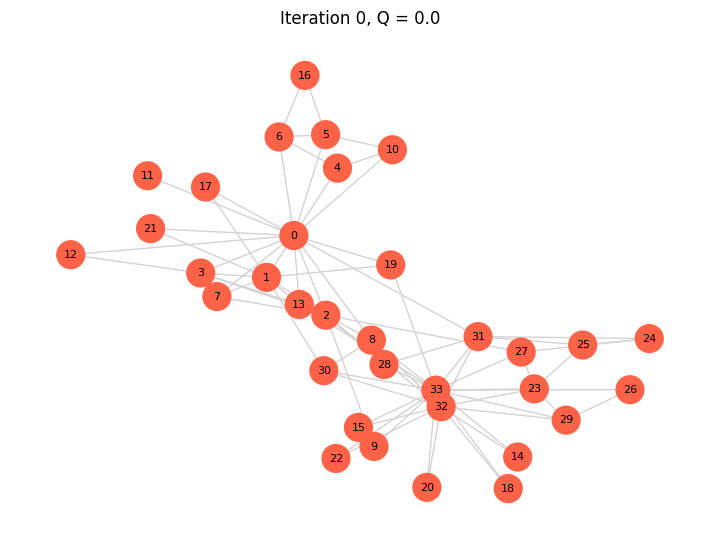

,community,degree,betweenness,closeness,clustering
node,,,,,
33,0,0.515,0.304,0.550,0.110
0,0,0.485,0.438,0.569,0.150
32,0,0.364,0.145,0.516,0.197
2,0,0.303,0.144,0.559,0.244
1,0,0.273,0.054,0.485,0.333
3,0,0.182,0.012,0.465,0.667
31,0,0.182,0.138,0.541,0.200
23,0,0.152,0.018,0.393,0.400
8,0,0.152,0.056,0.516,0.500


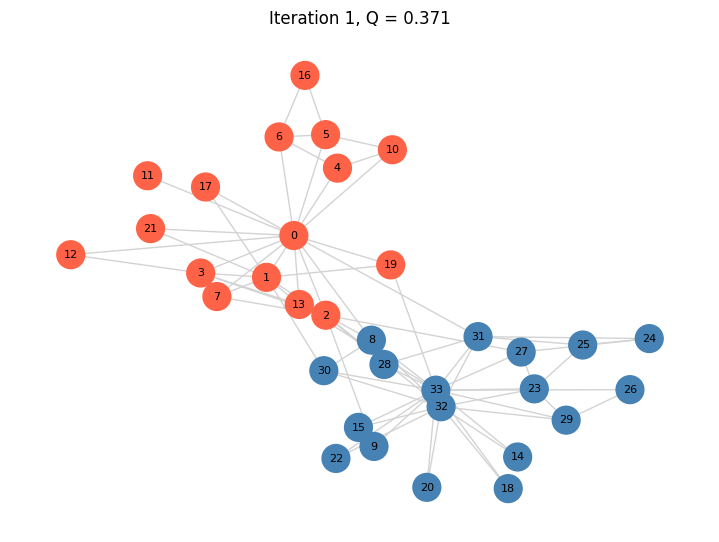

,community,degree,betweenness,closeness,clustering
node,,,,,
33,1,0.455,0.147,0.461,0.143
0,0,0.424,0.137,0.426,0.187
32,1,0.333,0.052,0.381,0.218
1,0,0.242,0.015,0.296,0.429
3,0,0.182,0.004,0.273,0.667
2,0,0.152,0.000,0.262,0.900
31,1,0.152,0.029,0.302,0.300
23,1,0.152,0.016,0.302,0.400
5,0,0.121,0.013,0.262,0.500


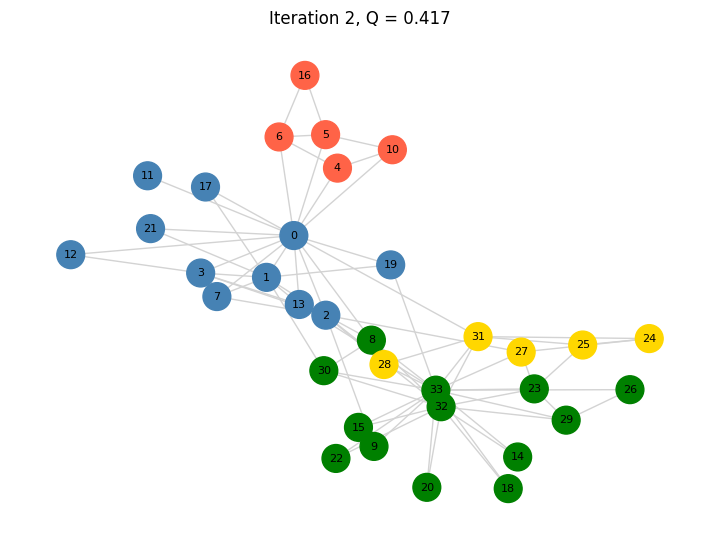

,community,degree,betweenness,closeness,clustering
node,,,,,
33,3,0.364,0.068,0.364,0.182
32,3,0.303,0.032,0.312,0.244
0,1,0.303,0.041,0.303,0.289
1,1,0.242,0.015,0.253,0.429
3,1,0.182,0.004,0.216,0.667
2,1,0.152,0.000,0.202,0.900
29,3,0.121,0.002,0.218,0.667
7,1,0.121,0.000,0.189,1.000
13,1,0.121,0.000,0.189,1.000


In [89]:
pos = nx.spring_layout(G, seed=42)

for i in range(len(all_history)):
    partition, Q = all_history[i]
    label = labels_per_iter[i]
    node_colors = [colors_list[label[n] % len(colors_list)] for n in G.nodes]

    plt.figure(figsize=(7, 5))
    nx.draw(G, pos, with_labels=True, node_color=node_colors,
            node_size=400, edge_color="lightgray", font_size=8)
    plt.title("Iteration " + str(i) + ", Q = " + str(np.round(Q, 3)))
    plt.show()

    df = make_table(i).sort_values("degree", ascending=False)
    display(df.style.format("{:.3f}", subset=["degree", "betweenness", "closeness", "clustering"])
            .background_gradient(cmap="YlOrRd", subset=["degree"])
            .background_gradient(cmap="Blues", subset=["betweenness"])
            .background_gradient(cmap="Greens", subset=["closeness"])
            .background_gradient(cmap="Purples", subset=["clustering"]))

In [93]:
# Trace node 11's eigenvector entry at each iteration
prev = [list(range(34))]
for i, (part, Q) in enumerate(history, start=1):
    g = [c for c in prev if 11 in c][0]          # group containing node 11 BEFORE this split
    l, v = al.eigh(get_part(g))
    u = v[:, -1]
    idx = {node: a for a, node in enumerate(g)}
    print(f"Iteration {i}: group size {len(g)}, lambda1 = {l[-1]:.4f}")
    print(f"   |u[11]| = {abs(u[idx[11]]):.4f}   |u[0]| = {abs(u[idx[0]]):.4f}   (threshold {T})")
    print("   node 11 undecided (|u| <= threshold):", abs(u[idx[11]]) <= T)
    prev = part

Iteration 1: group size 34, lambda1 = 4.9771
   |u[11]| = 0.0778   |u[0]| = 0.3875   (threshold 0.03)
   node 11 undecided (|u| <= threshold): False
Iteration 2: group size 16, lambda1 = 2.9441
   |u[11]| = 0.0129   |u[0]| = 0.0067   (threshold 0.03)
   node 11 undecided (|u| <= threshold): True


### What the splits show
| Iteration | Communities | Q |
|---|---|---|
| 1 | 2 | 0.3715 |
| 2 | 4 | 0.4174 |

- **Iteration 1:** the first split gives groups of 16 and 18 nodes. Compared with
  the real faction split (`G.nodes[i]['club']`), only node 8 is on the wrong side.
- **Iteration 2:** each group splits again, giving 4 communities. Node 11 stays
  with node 0 because its near-zero eigenvector entry is treated as undecided
  and its modularity weight points to node 0's group.
- With the handout's plain sign rule there would be a third iteration that
  isolates node 11, giving 5 communities with Q = 0.4094.
- Q rises at every step.

In [90]:
summary = []
for i in range(len(all_history)):
    row = {"iteration": i}
    for name in ["degree", "betweenness", "closeness", "clustering"]:
        values = metrics[name][i]
        top3 = sorted(values, key=values.get, reverse=True)[:3]
        row[name + " top 3"] = top3
    summary.append(row)

display(pd.DataFrame(summary).set_index("iteration"))

,degree top 3,betweenness top 3,closeness top 3,clustering top 3
iteration,,,,
0,"[33, 0, 32]","[0, 33, 32]","[0, 2, 33]","[7, 12, 14]"
1,"[33, 0, 32]","[33, 0, 32]","[33, 0, 32]","[7, 8, 12]"
2,"[33, 0, 32]","[33, 0, 32]","[33, 32, 0]","[7, 8, 12]"


In [91]:
evolution = {}
for name in metrics:
    table = pd.DataFrame({i: metrics[name][i] for i in metrics[name]})   # rows: nodes, columns: iterations
    evolution[name] = table

display(evolution["degree"].style.format("{:.3f}").background_gradient(cmap="YlOrRd", axis=None)
        .set_caption("Degree centrality: node (rows) by iteration (columns)"))

,0,1,2
0,0.485,0.424,0.303
1,0.273,0.242,0.242
2,0.303,0.152,0.152
3,0.182,0.182,0.182
4,0.091,0.091,0.061
5,0.121,0.121,0.091
6,0.121,0.121,0.091
7,0.121,0.121,0.121
8,0.152,0.091,0.091
9,0.061,0.030,0.030


## 9. Evolution of the metrics
Each plot has the iteration on the x-axis and one metric on the y-axis, with one
line per node. Nodes 0 and 33, the two faction leaders, are highlighted. Lines
that fall sharply belong to nodes that lost many cross-community edges.

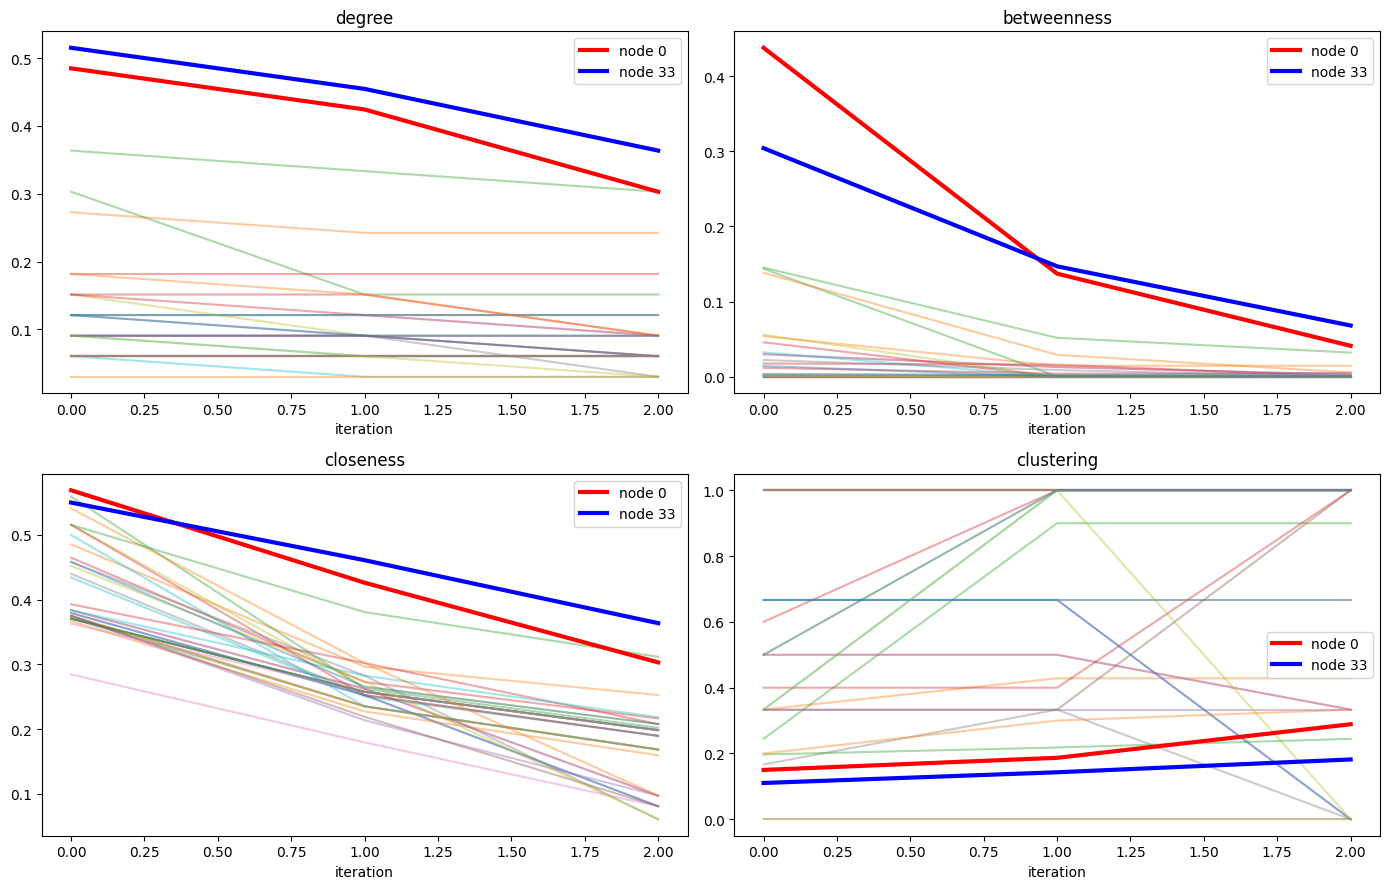

In [92]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, name in zip(axes.ravel(), evolution):
    for node in G.nodes:
        ax.plot(evolution[name].columns, evolution[name].loc[node], alpha=0.4)
    for node, color in [(0, "red"), (33, "blue")]:
        ax.plot(evolution[name].columns, evolution[name].loc[node], color=color, lw=3, label="node " + str(node))
    ax.set_title(name); ax.set_xlabel("iteration"); ax.legend()
plt.tight_layout()
plt.show()

## 10. Discussion
**Nodes that stay central.** [Name the nodes, probably 0 and 33, and quote their
values at iteration 0 and at the last iteration.] They remain at the top of
degree, betweenness and closeness because each is the center of its own
community, so removing cross edges costs them little.

**Nodes that change most.** [Name the nodes, e.g. 2, 8, 13, 31, with numbers.]
These sit between the two factions, so their cross-community edges are removed
and their betweenness and degree drop.

**How community structure affects the metrics.**
- *Degree* falls for nodes with many cross-community edges.
- *Betweenness* changes the most: once communities are disconnected, shortest
  paths cannot cross between them, so bridge nodes lose their special role.
- *Closeness* falls because distances grow or nodes become unreachable.
- *Clustering* tends to rise for nodes whose removed edges were the ones that
  did not close triangles inside their group. [Check this against your plots.]

Overall, the metrics show that a node's importance depends on whether it is a
**hub inside a community** or a **bridge between communities**.